Accuracy on this data: 1.0


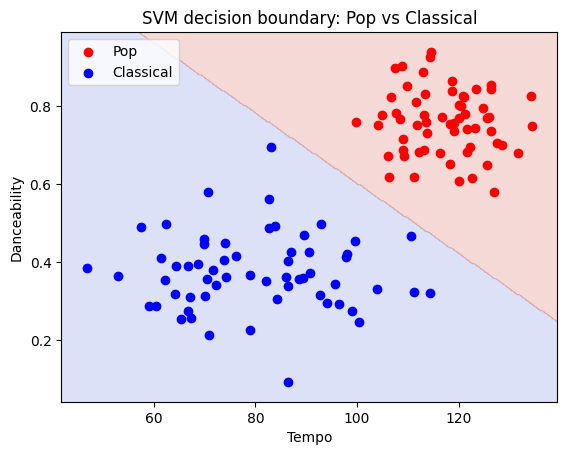

In [1]:
#Task 1: SVM to separate Pop and Classical songs and plot the decision boundary
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

mg = pd.read_csv("music_genres.csv")
X = mg[["tempo", "danceability"]]
y = (mg["genre"] == "Pop").astype(int)

svm = make_pipeline(StandardScaler(), SVC(kernel="linear"))
svm.fit(X, y)
print("Accuracy on this data:", round(svm.score(X, y), 3))

# draw the boundary on a grid of tempo and danceability values
gx, gy = np.meshgrid(np.linspace(X.tempo.min() - 5, X.tempo.max() + 5, 300),
                     np.linspace(X.danceability.min() - 0.05, X.danceability.max() + 0.05, 300))
grid = pd.DataFrame({"tempo": gx.ravel(), "danceability": gy.ravel()})
zz = svm.predict(grid).reshape(gx.shape)

plt.contourf(gx, gy, zz, alpha=0.2, cmap="coolwarm")
plt.scatter(X.tempo[y == 1], X.danceability[y == 1], color="red", label="Pop")
plt.scatter(X.tempo[y == 0], X.danceability[y == 0], color="blue", label="Classical")
plt.xlabel("Tempo")
plt.ylabel("Danceability")
plt.title("SVM decision boundary: Pop vs Classical")
plt.legend()
plt.show()

In [2]:
#Task 2: Linear SVM for Flipkart review sentiment
from sklearn.feature_extraction.text import CountVectorizer

rv = pd.read_csv("flipkart_reviews.csv")
xtr, xte, ytr, yte = train_test_split(rv["review"], rv["label"], test_size=0.25, random_state=1, stratify=rv["label"])

cv = CountVectorizer()
xtr_n = cv.fit_transform(xtr)
xte_n = cv.transform(xte)

lsvm = SVC(kernel="linear")
lsvm.fit(xtr_n, ytr)
print("Accuracy:", round(accuracy_score(yte, lsvm.predict(xte_n)), 3))

Accuracy: 1.0


In [3]:
#Task 3: Polynomial vs RBF kernel on IPL player performance
ip = pd.read_csv("ipl_performance.csv")
X = ip[["batting_avg", "strike_rate"]]
y = ip["performance"]
xtr, xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

for k in ["poly", "rbf"]:
    m = make_pipeline(StandardScaler(), SVC(kernel=k))
    m.fit(xtr, ytr)
    print(k, "kernel -> train accuracy:", round(m.score(xtr, ytr), 3), "test accuracy:", round(m.score(xte, yte), 3))

# RBF did slightly better (0.967) than polynomial (0.95).
# Whether a player is high or low performing depends on batting average and strike rate together, and the boundary is curved.
# RBF can make a smooth flexible curve, while a degree 3 polynomial is more rigid.
# The gap is small (about 2 players out of 120 in the test set), so both kernels work well.

poly kernel -> train accuracy: 0.929 test accuracy: 0.95
rbf kernel -> train accuracy: 0.943 test accuracy: 0.967


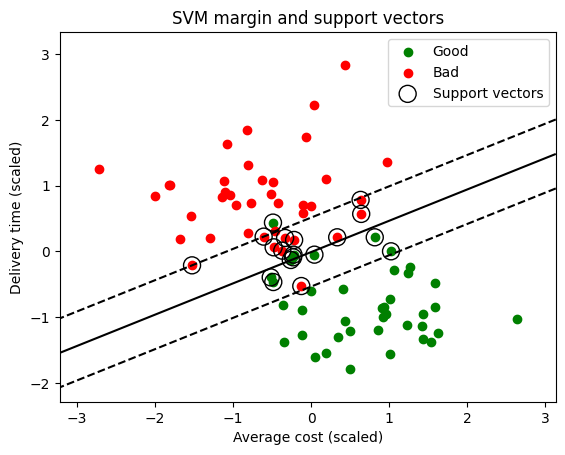

Number of support vectors: 19
Accuracy: 0.938


In [4]:
#Task 4: Plot margin and support vectors for Zomato Good vs Bad restaurants
zg = pd.read_csv("zomato_good_bad.csv")
Xz = StandardScaler().fit_transform(zg[["avg_cost", "delivery_time"]])
yz = (zg["rating_class"] == "Good").astype(int).values

sv = SVC(kernel="linear", C=1)
sv.fit(Xz, yz)

gx, gy = np.meshgrid(np.linspace(Xz[:, 0].min() - 0.5, Xz[:, 0].max() + 0.5, 300),
                     np.linspace(Xz[:, 1].min() - 0.5, Xz[:, 1].max() + 0.5, 300))
dec = sv.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

plt.scatter(Xz[yz == 1, 0], Xz[yz == 1, 1], color="green", label="Good")
plt.scatter(Xz[yz == 0, 0], Xz[yz == 0, 1], color="red", label="Bad")
plt.contour(gx, gy, dec, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"])
plt.scatter(sv.support_vectors_[:, 0], sv.support_vectors_[:, 1], s=150, facecolors="none", edgecolors="black", label="Support vectors")
plt.xlabel("Average cost (scaled)")
plt.ylabel("Delivery time (scaled)")
plt.title("SVM margin and support vectors")
plt.legend()
plt.show()

print("Number of support vectors:", len(sv.support_vectors_))
print("Accuracy:", round(sv.score(Xz, yz), 3))

# The solid line is the decision boundary and the dashed lines are the margin.
# The circled points are the support vectors. They are the points on or inside the margin, and only they decide where the line is.
# If other points move away from the line, the boundary does not change.